# Gradient Boosting od intuicji do kompletnego pipeline’u
## Warsztat scikit-learn • 100 000 obserwacji • klasyfikacja binarna

**Cel:** wykrywać rzadką klasę "1" w kontrolowanym, syntetycznym problemie tablicowym. Dane nie opisują prawdziwych klientów ani pacjentów. Wysoki wynik na tych danych nie dowodzi skuteczności w realnym zastosowaniu.





**Warianty:** `FULL` = 100 000 wierszy, 6 konfiguracji × 3 foldy; `QUICK` = 20 000 wierszy, 3 konfiguracje × 3 foldy. Czas zależy od CPU; poniżej mierzymy go zamiast obiecywać konkretny czas.

In [1]:
# W nowym środowisku odkomentuj i uruchom, a następnie zrestartuj kernel.
# %pip install scikit-learn==1.8.0 numpy==2.3.5 pandas==2.2.3 matplotlib==3.10.8 scipy==1.17.0 joblib==1.5.3 threadpoolctl==3.6.0
# Dla lokalnego Jupytera dodatkowo: python -m pip install jupyterlab

### 1. Powtarzalność i kontrola zasobów
Stałe ziarno losowości stabilizuje podział danych i losowanie konfiguracji. Pełna zgodność bitowa zależy również od wersji bibliotek i platformy. Ograniczamy wątki: wiele procesów CV i wiele wątków OpenMP naraz może spowolnić komputer. Tu wyszukiwanie działa sekwencyjnie, a pojedynczy model wykorzystuje maksymalnie cztery wątki.

**Powiedz:** „Zanim porównamy modele, ustalamy warunki eksperymentu. Inaczej różnicę wyników łatwo pomylić ze skutkiem innego podziału danych”.

In [2]:
import os, sys, json, time, platform, warnings
from pathlib import Path
os.environ['OMP_NUM_THREADS'] = '4'
os.environ['OPENBLAS_NUM_THREADS'] = '4'
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, joblib
from IPython.display import display, Markdown
from threadpoolctl import threadpool_limits
from sklearn.base import clone
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, RandomizedSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.ensemble import HistGradientBoostingClassifier, GradientBoostingRegressor
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, balanced_accuracy_score, precision_score, recall_score,
    f1_score, roc_auc_score, average_precision_score, log_loss, brier_score_loss,
    precision_recall_curve, confusion_matrix, classification_report,
    RocCurveDisplay, PrecisionRecallDisplay, ConfusionMatrixDisplay)
from sklearn.calibration import calibration_curve
from sklearn.inspection import permutation_importance, PartialDependenceDisplay

LIMITER = threadpool_limits(limits=4)
SEED = 42
MODE = 'FULL'  # zmień na QUICK, jeśli chcesz krótsze ćwiczenie
assert MODE in {'FULL', 'QUICK'}
N_SAMPLES = 100_000 if MODE == 'FULL' else 20_000
N_SEARCH = 6 if MODE == 'FULL' else 3
OUT = Path('gradient_boosting_outputs')
OUT.mkdir(exist_ok=True)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.figsize': (10, 5), 'figure.dpi': 110, 'axes.spines.top': False,
                     'axes.spines.right': False, 'font.size': 11})
VERSIONS = {'python': platform.python_version(), 'scikit-learn': sklearn.__version__,
            'numpy': np.__version__, 'pandas': pd.__version__, 'scipy': scipy.__version__,
            'joblib': joblib.__version__}
print('Środowisko:', VERSIONS)
print(f'Tryb {MODE}: {N_SAMPLES:,} rekordów; {N_SEARCH} konfiguracji × 3 foldy')
run_start = time.perf_counter()

def finish_plot(name):
    plt.tight_layout()
    plt.savefig(OUT / f'{name}.png', dpi=140, bbox_inches='tight')
    plt.show()

Środowisko: {'python': '3.12.14', 'scikit-learn': '1.8.0', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'joblib': '1.5.3'}
Tryb FULL: 100,000 rekordów; 6 konfiguracji × 3 foldy


### 2. Co właściwie robi gradient boosting?
Model rośnie addytywnie: $F_m(x)=F_{m-1}(x)+\eta h_m(x)$, gdzie $h_m$ jest kolejnym drzewem, a $\eta$ to `learning_rate`. Nowe drzewo uczy się kierunku korekty bieżących błędów. Dla straty kwadratowej kierunek ten jest proporcjonalny do reszty $y-\hat y$. W klasyfikacji używamy straty logarytmicznej; reszty nie są po prostu błędami etykiet 0/1. Dla binarnego log loss pochodna względem wyniku w skali logit wynosi $p-y$, a ujemny gradient $y-p$. Implementacja histogramowa wykorzystuje również informacje drugiego rzędu przy wyznaczaniu wartości liści.

Poniższa **osobna demonstracja regresyjna** pokazuje kolejne przybliżenia funkcji. To nie jest główny problem klasyfikacyjny. `GradientBoostingRegressor` jest tu użyty celowo, aby łatwo zobaczyć etapy.

**Powiedz:** „Pierwsze drzewo nie musi rozwiązać całego zadania. Każde następne dodaje korektę. Mały krok oznacza zwykle potrzebę większej liczby drzew”.

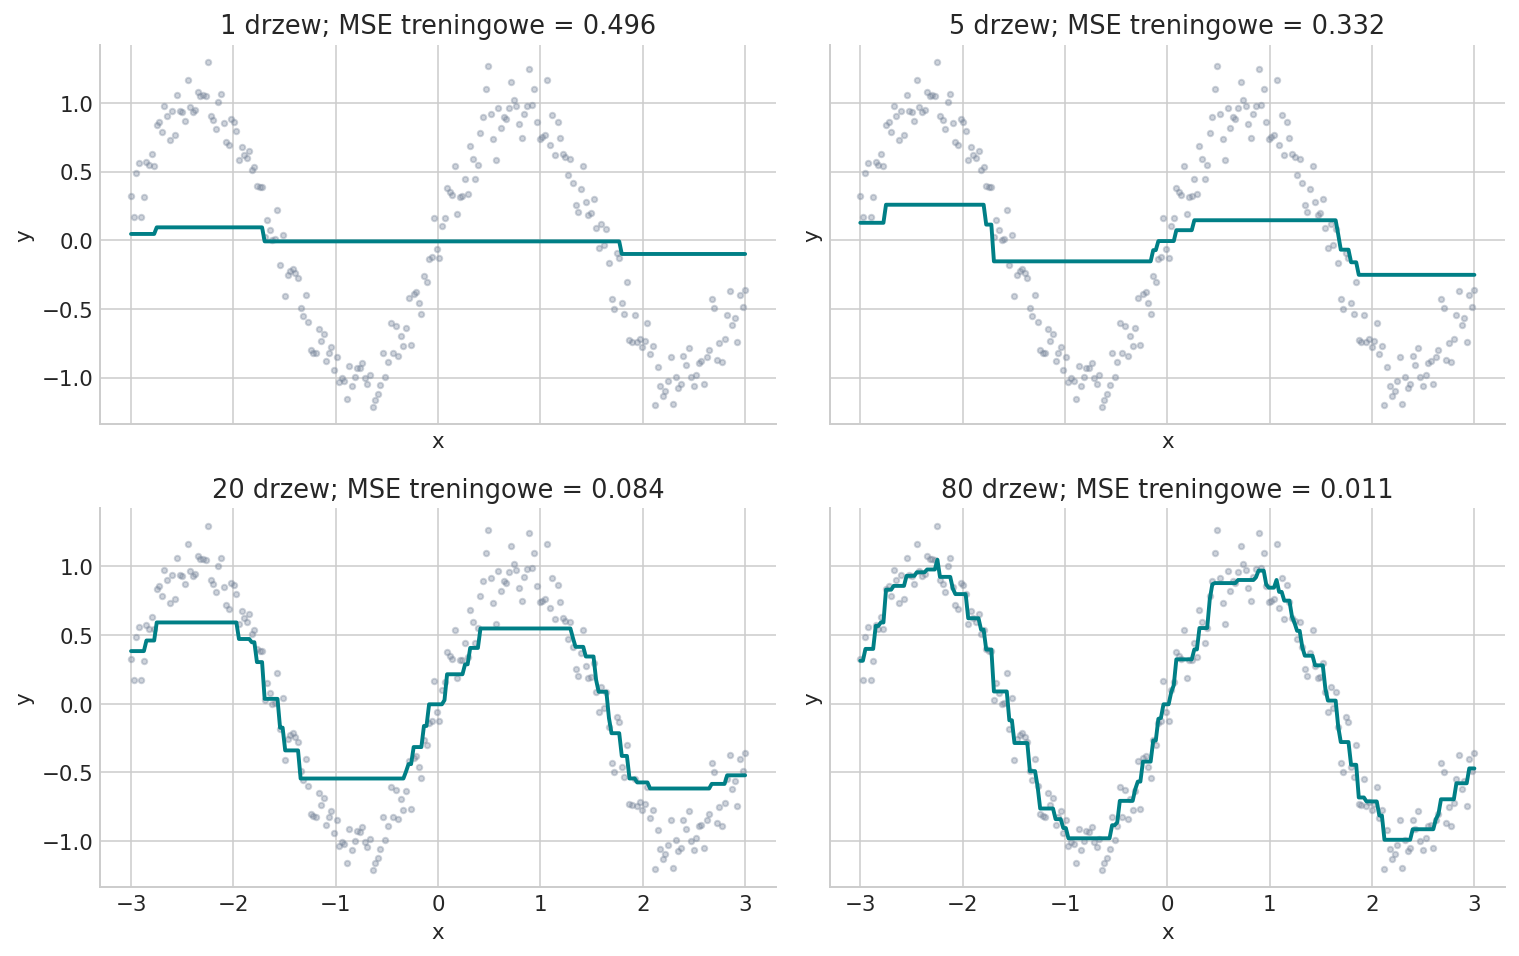

In [3]:
rng_demo = np.random.default_rng(SEED)
x_demo = np.linspace(-3, 3, 240).reshape(-1, 1)
y_demo = np.sin(2*x_demo[:, 0]) + 0.15*rng_demo.normal(size=len(x_demo))
demo = GradientBoostingRegressor(n_estimators=80, learning_rate=0.12, max_depth=2, random_state=SEED)
demo.fit(x_demo, y_demo)
stages = {i: p for i, p in enumerate(demo.staged_predict(x_demo), start=1) if i in {1, 5, 20, 80}}
fig, axes = plt.subplots(2, 2, figsize=(11, 7), sharex=True, sharey=True)
for ax, (i, p) in zip(axes.flat, stages.items()):
    ax.scatter(x_demo[:, 0], y_demo, s=8, alpha=.35, color='#758398')
    ax.plot(x_demo[:, 0], p, color='#007f86', lw=2)
    ax.set_title(f'{i} drzew; MSE treningowe = {np.mean((y_demo-p)**2):.3f}')
    ax.set_xlabel('x'); ax.set_ylabel('y')
finish_plot('01_intuicja_boostingu')

### 3. Duży zbiór danych i jego ograniczenia
Generujemy **100 000 wierszy i 26 cech**: 24 liczbowe oraz 2 kategoryczne. Wśród cech liczbowych jest 12 informacyjnych, 6 redundantnych (kombinacje informacyjnych) i 6 szumowych. `shuffle=False` zachowuje tę kolejność — znamy prawdę generatora i możemy sprawdzić interpretację modelu. Klasa 1 stanowi około 12%; losowe zmiany etykiet (`flip_y=0.02`) nieco zmieniają ten udział.

Dwie kategorie są deterministycznymi przekształceniami cech liczbowych. **Nie dostarczają niezależnej informacji**; służą demonstracji obsługi różnych typów. Progi kategorii są ustalone z góry, nie estymowane z testu. Braki w 2% pól liczbowych wprowadzamy niezależnie od etykiety (MCAR). W praktyce mechanizm braków bywa znacznie bardziej złożony.

**Powiedz:** „Duży zbiór nie usuwa problemu jakości danych. Celowo dodajemy szum, nadmiarowe kolumny i braki, aby pipeline miał rzeczywiste zadanie”.

In [4]:
X_array, y_array = make_classification(
    n_samples=N_SAMPLES, n_features=24, n_informative=12, n_redundant=6,
    n_repeated=0, n_clusters_per_class=2, weights=[0.88, 0.12],
    class_sep=1.0, flip_y=0.02, shuffle=False, random_state=SEED)
num_cols = [f'x{i:02d}' for i in range(24)]
cat_cols = ['pasmo_x00', 'znak_x01']
X = pd.DataFrame(X_array.astype('float32'), columns=num_cols)
X['pasmo_x00'] = np.select([X.x00 < -1, X.x00 > 1], ['A', 'C'], default='B')
X['znak_x01'] = np.where(X.x01 >= 0, 'plus', 'minus')
rng = np.random.default_rng(SEED + 1)
X[num_cols] = X[num_cols].mask(rng.random((N_SAMPLES, len(num_cols))) < .02)
y = pd.Series(y_array, name='target', index=X.index)
feature_roles = pd.Series(['informacyjna']*12 + ['redundantna']*6 + ['szumowa']*6,
                          index=num_cols, name='rola_generatora')
assert X.shape == (N_SAMPLES, 26) and set(y.unique()) == {0, 1}
assert X.index.is_unique and not y.isna().any()
print(f'X: {X.shape}; RAM ramki: {X.memory_usage(deep=True).sum()/1024**2:.1f} MiB')

X: (100000, 26); RAM ramki: 19.0 MiB


### 4. Trzy rozłączne części i trzy różne role
| Część | Udział | Zastosowanie |
|---|---:|---|
| Train | 60% | EDA, preprocessing, CV, wybór hiperparametrów i trening |
| Validation | 20% | Ustalenie progu F1 i diagnostyka przed końcowym testem |
| Test | 20% | Jednorazowa ocena zamrożonego modelu i progu |

W CV dzielimy **wyłącznie train** na 3 foldy. Każdy model HGB wydziela dodatkowo 10% swojego treningowego foldu do early stopping. Fold oceniający CV nie jest używany do zatrzymania treningu. Osobny validation nie steruje hiperparametrami — wybór progu jest jego główną rolą.

Nie dopasowujemy ponownie finalnego modelu na train+validation po wybraniu progu: mogłoby to zmienić rozkład prawdopodobieństw i unieważnić wybrany próg. W produkcji większy zbiór treningowy wymaga nowego, poprawnie zaplanowanego procesu walidacji.

**Założenie:** niezależne obserwacje z tego samego rozkładu (IID). Dla danych czasowych stosuj podział chronologiczny; dla wielu rekordów tej samej osoby — podział grupowy. Stratyfikacja nie chroni przed tymi rodzajami przecieku.

In [5]:
X_dev, X_test, y_dev, y_test = train_test_split(X, y, test_size=.2, stratify=y, random_state=SEED)
X_train, X_val, y_train, y_val = train_test_split(X_dev, y_dev, test_size=.25,
                                               stratify=y_dev, random_state=SEED)
assert set(X_train.index).isdisjoint(X_val.index)
assert set(X_train.index).isdisjoint(X_test.index)
assert set(X_val.index).isdisjoint(X_test.index)
assert len(X_train) + len(X_val) + len(X_test) == len(X)
display(pd.DataFrame({'część':['train','validation','test'],
                      'wiersze':[len(X_train), len(X_val), len(X_test)]}))
# Dalsza eksploracja dotyczy tylko train. Test pozostaje zamknięty do sekcji 14.
display(X_train.head())

        część  wiersze
0       train    60000
1  validation    20000
2        test    20000

            x00       x01       x02  ...       x23  pasmo_x00  znak_x01
84107 -3.820292  0.267089  2.397258  ...  0.878747          A      plus
64943 -2.558487 -5.297226 -1.076783  ...  2.972909          A     minus
18718  3.712058  2.508844 -0.783323  ...  0.241950          C      plus
96854  2.611340  4.112846 -0.750878  ...  0.382293          C      plus
32385  0.003467 -2.556196 -1.241435  ... -0.435440          B     minus

[5 rows x 26 columns]

### 5. EDA na treningu: klasy, braki i korelacje
Zwróć uwagę na wysoką częstość klasy 0: model zawsze przewidujący 0 osiągnie wysokie accuracy, mimo że nie wykryje ani jednego pozytywu. Korelacje cech redundantnych utrudnią późniejszą interpretację pojedynczych ważności.

**Powiedz:** „Accuracy odpowiada, jak często trafiam ogółem. W zadaniu z rzadkimi zdarzeniami ważniejsze może być, ile zdarzeń wykrywam i jak wiele alarmów okazuje się fałszywych”.

Udział klasy 1 na train: 12.78%
Accuracy strategii zawsze 0: 87.22%; recall klasy 1: 0%


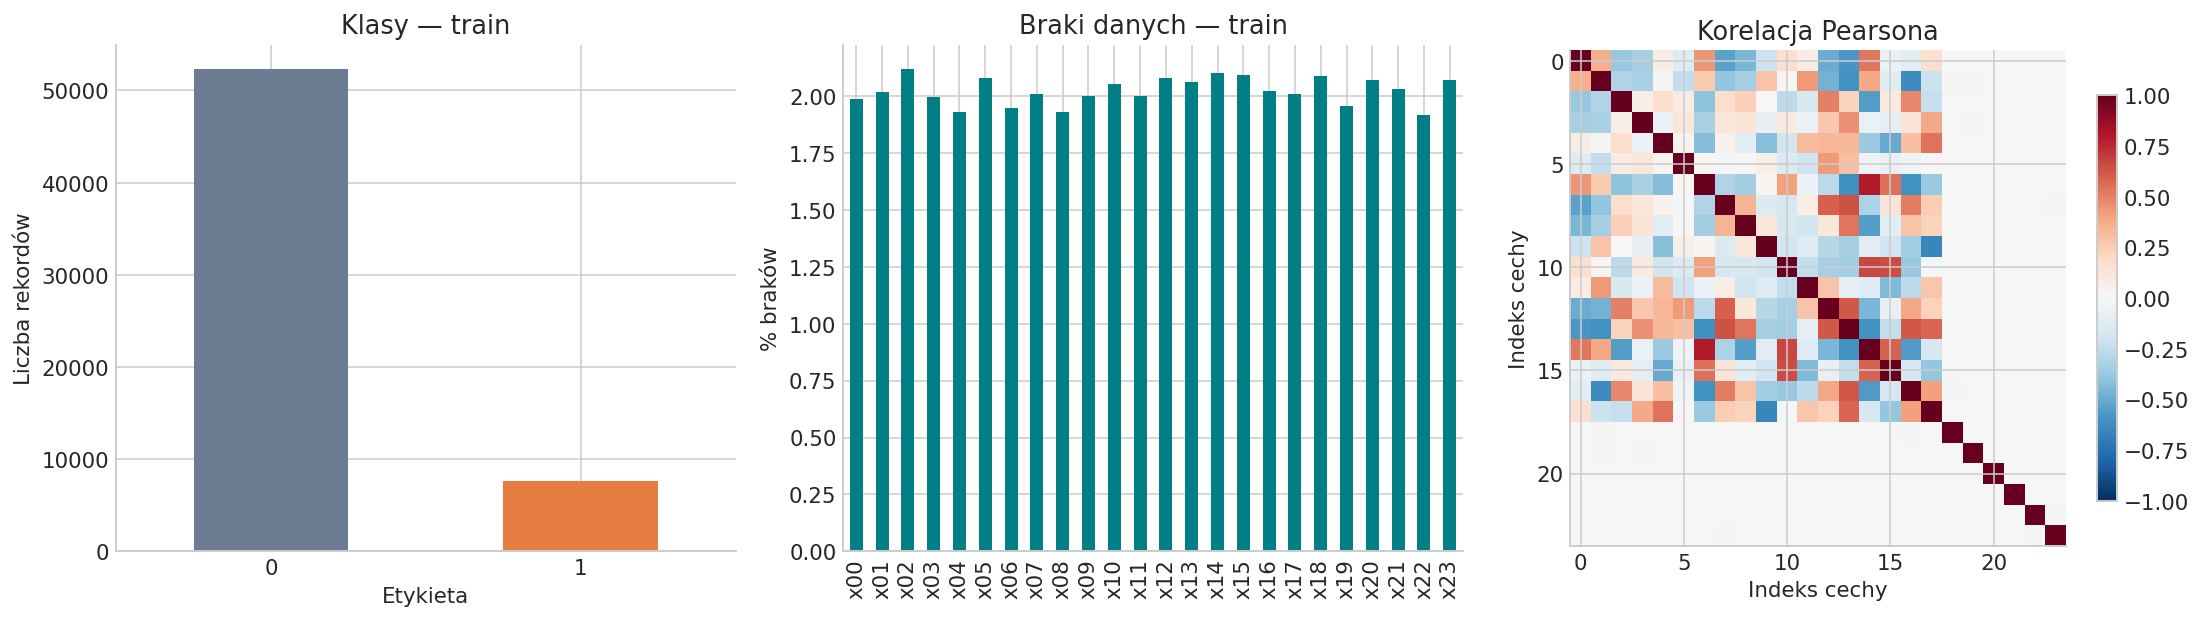

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.6))
y_train.value_counts().sort_index().plot.bar(ax=axes[0], color=['#6b7c93','#e67e42'], rot=0)
axes[0].set(title='Klasy — train', xlabel='Etykieta', ylabel='Liczba rekordów')
(X_train[num_cols].isna().mean()*100).plot.bar(ax=axes[1], color='#007f86')
axes[1].set(title='Braki danych — train', ylabel='% braków')
corr = X_train[num_cols].corr()
im = axes[2].imshow(corr, cmap='RdBu_r', vmin=-1, vmax=1)
axes[2].set(title='Korelacja Pearsona', xlabel='Indeks cechy', ylabel='Indeks cechy')
fig.colorbar(im, ax=axes[2], shrink=.8)
finish_plot('02_eda')
print(f'Udział klasy 1 na train: {y_train.mean():.2%}')
print(f'Accuracy strategii zawsze 0: {1-y_train.mean():.2%}; recall klasy 1: 0%')

### 6. Pipeline: preprocessing pozostaje wewnątrz walidacji
Główny model to `HistGradientBoostingClassifier`. Histogramy grupują wartości liczbowe w ograniczoną liczbę przedziałów, co przyspiesza poszukiwanie podziałów przy dużej liczbie wierszy. Model obsługuje braki liczbowe natywnie; nie potrzebuje skalowania. `max_iter` oznacza liczbę iteracji boostingu, a w naszym problemie binarnym jedną iterację reprezentuje jedno drzewo.

`ColumnTransformer` zachowuje liczby i koduje kategorie. Indeksy kolumn kategorycznych przekazujemy jawnie do modelu — dzięki temu kody 0/1/2 nie zostaną potraktowane jako pomiar ciągły. Słowniki kategorii są określone z góry, a nieznane wartości są mapowane na `NaN` i obsługiwane jak braki. W realnym zbiorze słownik można uczyć tylko na treningu, kontrolując liczbę kategorii.

Regresja logistyczna potrzebuje osobnego przetwarzania: imputacji, skalowania liczb i one-hot kategorii. Wszystkie kroki dopasowywane są wewnątrz każdego foldu. Dummy stanowi punkt odniesienia.

In [7]:
cat_levels = [['A', 'B', 'C'], ['minus', 'plus']]
pre_hgb = ColumnTransformer([
    ('num', 'passthrough', num_cols),
    ('cat', OrdinalEncoder(categories=cat_levels, handle_unknown='use_encoded_value',
                           unknown_value=np.nan, dtype=np.float64), cat_cols)
], verbose_feature_names_out=False)
hgb = Pipeline([
    ('preprocess', pre_hgb),
    ('model', HistGradientBoostingClassifier(
        categorical_features=[24, 25], learning_rate=.1, max_iter=220,
        max_leaf_nodes=31, min_samples_leaf=30, l2_regularization=1.,
        early_stopping=True, validation_fraction=.1, n_iter_no_change=15,
        scoring='loss', random_state=SEED))
])
pre_linear = ColumnTransformer([
    ('num', Pipeline([('impute', SimpleImputer(strategy='median', add_indicator=True)),
                      ('scale', StandardScaler())]), num_cols),
    ('cat', OneHotEncoder(categories=cat_levels, handle_unknown='ignore', sparse_output=False), cat_cols)
])
logistic = Pipeline([('preprocess', pre_linear),
                     ('model', LogisticRegression(max_iter=1000, random_state=SEED))])
dummy = Pipeline([('preprocess', clone(pre_linear)), ('model', DummyClassifier(strategy='prior'))])
print(hgb)

Pipeline(steps=[('preprocess',
                 ColumnTransformer(transformers=[('num', 'passthrough',
                                                  ['x00', 'x01', 'x02', 'x03',
                                                   'x04', 'x05', 'x06', 'x07',
                                                   'x08', 'x09', 'x10', 'x11',
                                                   'x12', 'x13', 'x14', 'x15',
                                                   'x16', 'x17', 'x18', 'x19',
                                                   'x20', 'x21', 'x22',
                                                   'x23']),
                                                 ('cat',
                                                  OrdinalEncoder(categories=[['A',
                                                                              'B',
                                                                              'C'],
                                                               

### 7. Baseline i walidacja krzyżowa
Główną metryką wyboru jest **Average Precision (AP)**: podsumowanie krzywej precision–recall bez ustalania progu. AP nie jest identyczne z polem liczonym metodą trapezów pod krzywą PR. Punkt odniesienia dla losowego rankingu zależy od częstości klasy 1. ROC AUC ocenia ranking pozytywów względem negatywów; nie opisuje liczby fałszywych alarmów dla konkretnego progu. Log loss karze błędne, pewne przewidywania; mniejszy jest lepszy.

Stosujemy te same foldy dla wszystkich modeli. Pokazywane odchylenie standardowe po foldach to opis zmienności, **nie** 95% przedział ufności. Wynik CV po przeszukaniu hiperparametrów może być optymistyczny — końcowy test pozostaje potrzebny.

Dummy: zakończono w 0.5 s
Logistic: zakończono w 1.0 s
HGB bazowy: zakończono w 4.0 s


,AP_CV,AP_std,ROC_AUC_CV,log_loss_CV,AP_train,czas_s
model,,,,,,
Dummy,0.1278,0.0000,0.5000,0.3822,0.1278,0.5289
Logistic,0.6559,0.0060,0.8567,0.2552,0.6595,1.0010
HGB bazowy,0.9088,0.0068,0.9558,0.1154,0.9801,4.0276


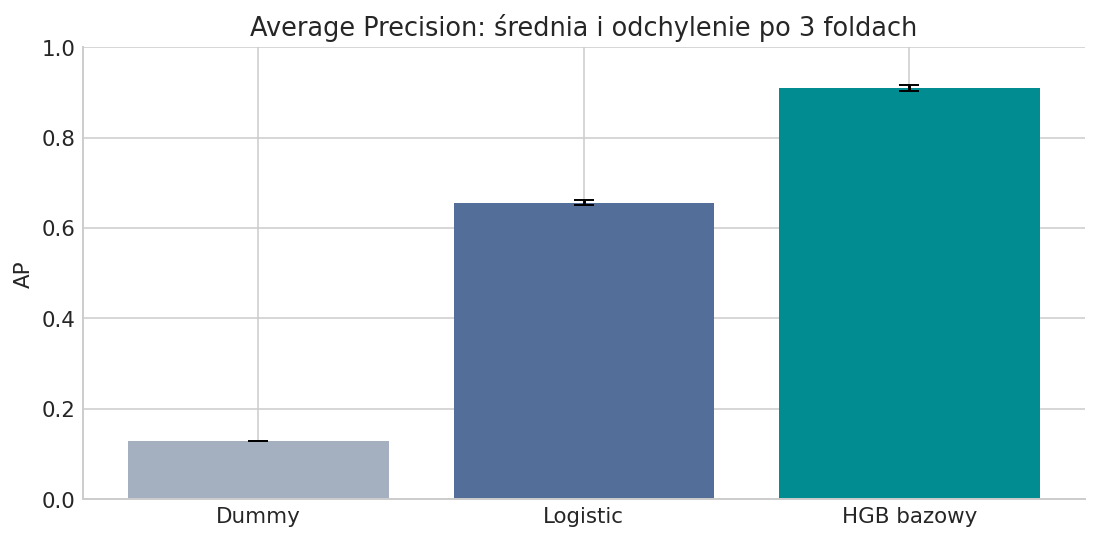

In [8]:
cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
scoring = {'ap':'average_precision', 'roc_auc':'roc_auc', 'neg_log_loss':'neg_log_loss'}
cv_rows, cv_raw = [], {}
for name, estimator in [('Dummy', dummy), ('Logistic', logistic), ('HGB bazowy', hgb)]:
    t0 = time.perf_counter()
    scores = cross_validate(estimator, X_train, y_train, cv=cv, scoring=scoring,
                            n_jobs=1, return_train_score=True, error_score='raise')
    cv_raw[name] = scores
    cv_rows.append({'model':name, 'AP_CV':scores['test_ap'].mean(),
                    'AP_std':scores['test_ap'].std(ddof=1),
                    'ROC_AUC_CV':scores['test_roc_auc'].mean(),
                    'log_loss_CV':-scores['test_neg_log_loss'].mean(),
                    'AP_train':scores['train_ap'].mean(),
                    'czas_s':time.perf_counter()-t0})
    print(f'{name}: zakończono w {cv_rows[-1]["czas_s"]:.1f} s', flush=True)
cv_table = pd.DataFrame(cv_rows).set_index('model')
display(cv_table.round(4))
fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(cv_table.index, cv_table.AP_CV, yerr=cv_table.AP_std, capsize=5,
       color=['#a4afbf','#546e9a','#008c91'])
ax.set(title='Average Precision: średnia i odchylenie po 3 foldach', ylabel='AP', ylim=(0,1))
finish_plot('03_baseline_cv')

### 8. Strojenie HGB: budżet zamiast pełnej siatki
`RandomizedSearchCV` losuje 6 konfiguracji z 81 możliwych. To mały budżet szkoleniowy, nie dowód znalezienia globalnego optimum. Parametry:
- `learning_rate`: siła pojedynczej korekty; mniejsza może wymagać większego `max_iter`;
- `max_leaf_nodes`: złożoność drzew i możliwość modelowania interakcji;
- `min_samples_leaf`: ogranicza drobne, niestabilne liście;
- `l2_regularization`: regularizacja wartości liści.

`refit='ap'` dopasuje najlepszą konfigurację na całym train, z wewnętrznym podzbiorem early stopping. Maksymalna liczba iteracji pozostaje 220. Nie włączamy automatycznie wag klas: zmieniają funkcję celu i mogą wpływać na interpretację prawdopodobieństw. Najpierw oceniamy model bez wag i dobieramy próg.

**Powiedz:** „Szukamy konfiguracji, która radzi sobie na niewidzianym foldzie. Idealny wynik treningowy sam w sobie nie jest celem”.

In [9]:
param_space = {
    'model__learning_rate':[.06, .10, .16],
    'model__max_leaf_nodes':[15, 31, 47],
    'model__min_samples_leaf':[20, 50, 100],
    'model__l2_regularization':[0., 1., 5.]
}
t0 = time.perf_counter()
search = RandomizedSearchCV(hgb, param_distributions=param_space, n_iter=N_SEARCH,
    scoring=scoring, refit='ap', cv=cv, n_jobs=1, random_state=SEED,
    return_train_score=True, error_score='raise', verbose=1)
search.fit(X_train, y_train)
search_seconds = time.perf_counter()-t0
best = search.best_estimator_
cv_results = pd.DataFrame(search.cv_results_).sort_values('rank_test_ap')
cols = ['rank_test_ap','mean_test_ap','std_test_ap','mean_train_ap','mean_fit_time','params']
with pd.option_context('display.max_colwidth', 130):
    display(cv_results[cols].reset_index(drop=True))
print('Wybrane parametry:', search.best_params_)
print(f'Czas strojenia i refit: {search_seconds:.1f} s')

Fitting 3 folds for each of 6 candidates, totalling 18 fits
Wybrane parametry: {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 31, 'model__learning_rate': 0.06, 'model__l2_regularization': 1.0}
Czas strojenia i refit: 24.9 s


   rank_test_ap  ...                                                                                                                       params
0             1  ...  {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 31, 'model__learning_rate': 0.06, 'model__l2_regularization': 1.0}
1             2  ...  {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 31, 'model__learning_rate': 0.06, 'model__l2_regularization': 1.0}
2             3  ...  {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 31, 'model__learning_rate': 0.16, 'model__l2_regularization': 0.0}
3             4  ...  {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__learning_rate': 0.16, 'model__l2_regularization': 0.0}
4             5  ...  {'model__min_samples_leaf': 50, 'model__max_leaf_nodes': 15, 'model__learning_rate': 0.06, 'model__l2_regularization': 1.0}
5             6  ...  {'model__min_samples_leaf': 20, 'model__max_leaf_nodes': 15, 'model__learning_rate': 0.06, 'model__l2_

### 9. Diagnostyka early stopping
Wykres dotyczy końcowego refitu na train. `train_score_` i `validation_score_` przy `scoring='loss'` przechowują ujemną stratę, więc odwracamy znak. Iteracja 0 to model początkowy. Walidacja z tego wykresu jest **wewnętrznym podzbiorem treningu**, a nie naszym osobnym validation.

Jeśli obie straty maleją aż do limitu, warto w nowym eksperymencie zwiększyć `max_iter`. Jeśli trening poprawia się, a walidacja pogarsza, pojawia się sygnał przeuczenia. Early stopping ogranicza niepotrzebny trening, ale nie stanowi gwarancji generalizacji.

Wykonane iteracje: 220 / 220
Osiągnięto limit iteracji.


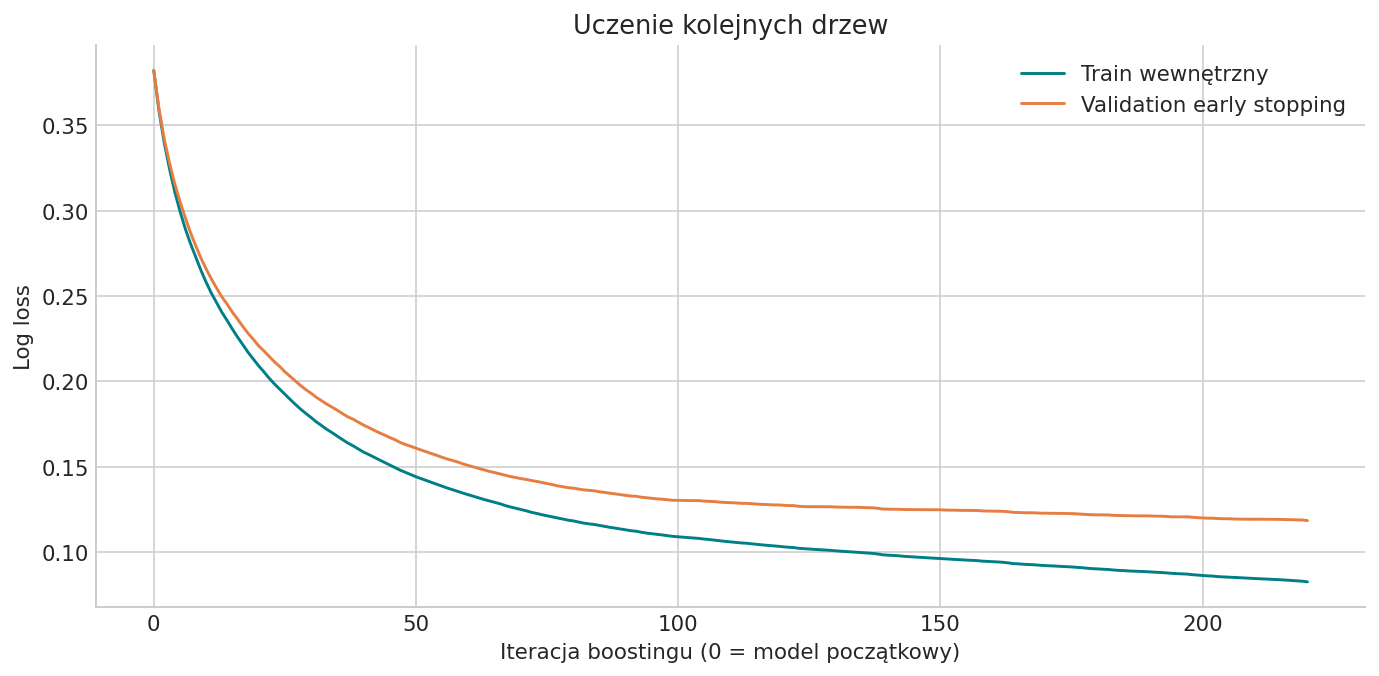

In [10]:
core = best.named_steps['model']
fig, ax = plt.subplots()
ax.plot(-core.train_score_, label='Train wewnętrzny', color='#007f86')
ax.plot(-core.validation_score_, label='Validation early stopping', color='#e67e42')
ax.set(xlabel='Iteracja boostingu (0 = model początkowy)', ylabel='Log loss', title='Uczenie kolejnych drzew')
ax.legend()
finish_plot('04_early_stopping')
print(f'Wykonane iteracje: {core.n_iter_} / {core.max_iter}')
print('Osiągnięto limit iteracji.' if core.n_iter_ == core.max_iter else 'Trening zatrzymano przed limitem.')

### 10. Próg decyzji dobieramy na validation
Model zwraca prawdopodobieństwo. Decyzja 0/1 wymaga progu. **Z góry przyjmujemy, że wybieramy próg maksymalizujący F1 na validation.** F1 równoważy precision i recall, ale pomija true negatives i nie jest uniwersalną funkcją wartości biznesowej.

Krzywa PR pozwala porównać wszystkie progi wynikające z unikalnych predykcji, a nie tylko rzadką siatkę 0.1, 0.2 itd. Przy identycznym maksymalnym F1 wybieramy najwyższy próg (mniej alarmów). Wynik F1 na validation po optymalizacji progu jest optymistyczny. Rzetelny wynik zobaczymy na test.

Wykres kosztu używa **umownych** wag FN=5, FP=1. To osobna analiza wrażliwości; nie zmienia przyjętego kryterium wyboru F1. Koszty w rzeczywistym projekcie należy ustalić z odbiorcą modelu przed wyborem progu.

Próg F1 wybrany na validation: 0.3062
F1 validation: próg 0.5 = 0.8557; wybrany = 0.8687


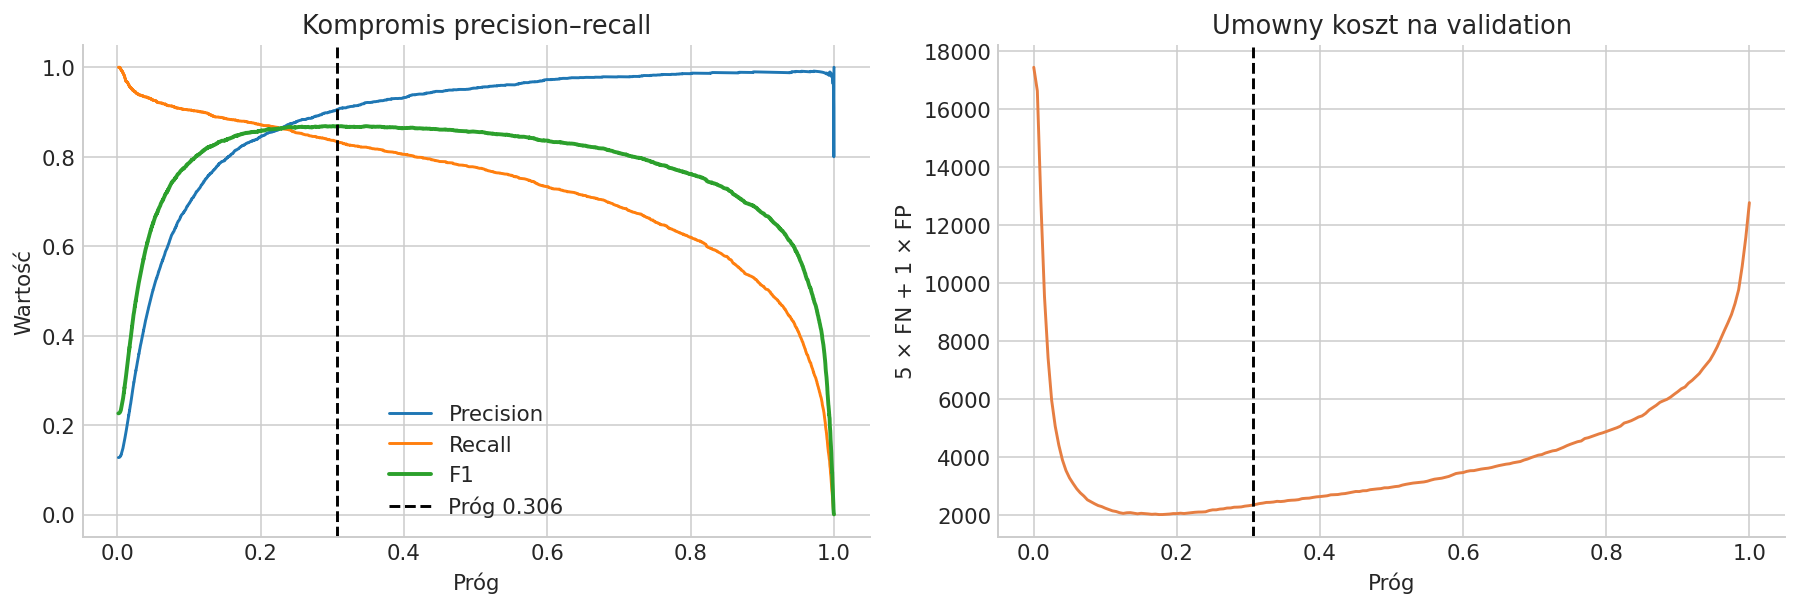

In [11]:
p_val = best.predict_proba(X_val)[:, 1]
pr, rc, thresholds = precision_recall_curve(y_val, p_val)
f1_values = 2*pr[:-1]*rc[:-1] / np.maximum(pr[:-1]+rc[:-1], 1e-15)
max_f1 = f1_values.max()
best_i = np.flatnonzero(np.isclose(f1_values, max_f1, rtol=0, atol=1e-12))[-1]
THRESHOLD = float(thresholds[best_i])
print(f'Próg F1 wybrany na validation: {THRESHOLD:.4f}')
print(f'F1 validation: próg 0.5 = {f1_score(y_val,p_val>=.5):.4f}; wybrany = {max_f1:.4f}')

grid = np.linspace(0, 1, 201)
threshold_rows=[]
for t in grid:
    tn, fp, fn, tp = confusion_matrix(y_val, p_val>=t, labels=[0,1]).ravel()
    threshold_rows.append({'threshold':t, 'cost':5*fn+fp, 'alarms':tp+fp})
threshold_table = pd.DataFrame(threshold_rows)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(thresholds, pr[:-1], label='Precision')
axes[0].plot(thresholds, rc[:-1], label='Recall')
axes[0].plot(thresholds, f1_values, label='F1', lw=2)
axes[0].axvline(THRESHOLD, color='black', ls='--', label=f'Próg {THRESHOLD:.3f}')
axes[0].set(xlabel='Próg', ylabel='Wartość', title='Kompromis precision–recall'); axes[0].legend()
axes[1].plot(grid, threshold_table.cost, color='#e67e42')
axes[1].axvline(THRESHOLD, color='black', ls='--')
axes[1].set(xlabel='Próg', ylabel='5 × FN + 1 × FP', title='Umowny koszt na validation')
finish_plot('05_prog_decyzji')

### 11. Ile daje większa próbka treningowa?
Dopasowujemy wybraną konfigurację na trzech wielkościach podzbioru train, za każdym razem z wewnętrznym early stopping. Porównujemy AP na treningu oraz **tym samym validation**. To pomocnicza diagnostyka po wyborze konfiguracji, nie niezależna walidacja ani kolejny sposób wyboru modelu.

Podzbiory są stratyfikowane, ale nie muszą być zagnieżdżone. Pojedyncza krzywa nie pokazuje niepewności wynikającej z losowania danych. Rosnący wynik walidacyjny może sugerować korzyść z dodatkowych danych; mała różnica train–validation sama w sobie nie gwarantuje dobrego modelu.

,n,AP_train,AP_val,czas_s,iteracje
0,5000,0.9889,0.8678,0.3321,137
1,20000,0.9822,0.9055,0.9902,220
2,60000,0.9517,0.9080,1.2643,220


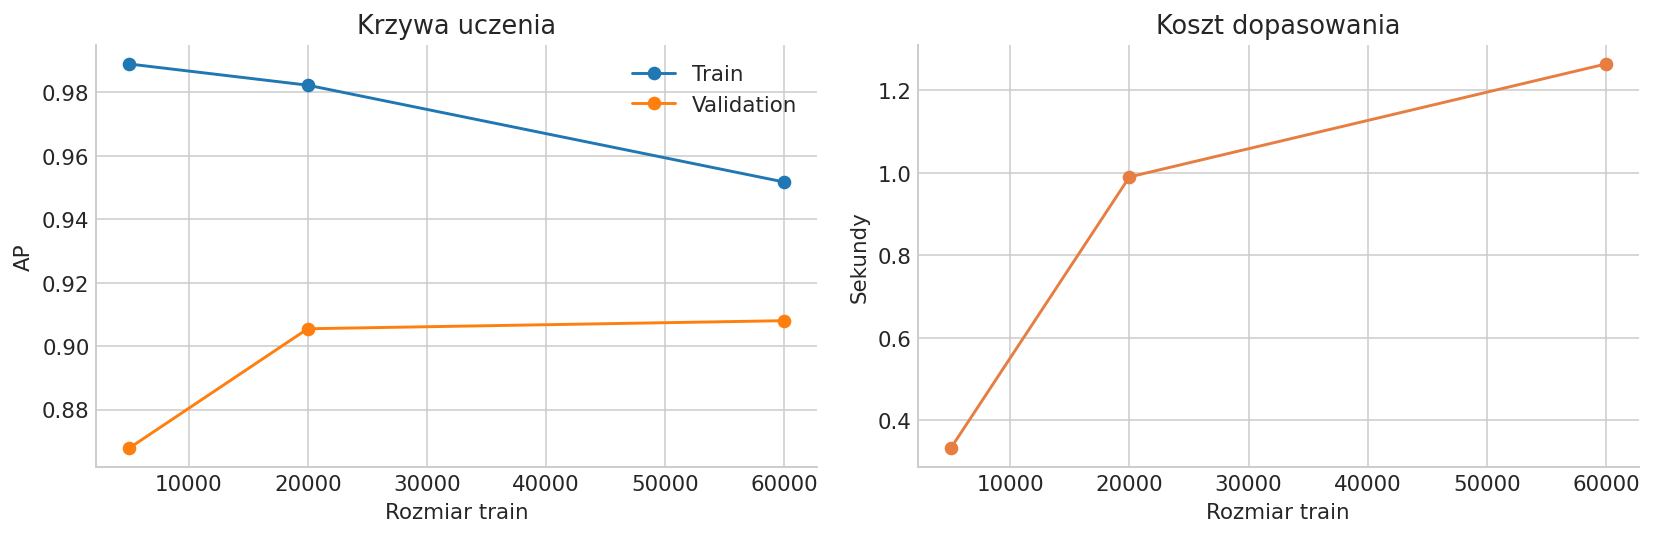

In [12]:
size_grid = sorted(set([min(5_000, len(X_train)//3), min(20_000, len(X_train)//2), len(X_train)]))
learning_rows=[]
for size in size_grid:
    if size == len(X_train):
        xs, ys, fitted, elapsed = X_train, y_train, best, float(search.refit_time_)
    else:
        ids, _ = train_test_split(np.arange(len(X_train)), train_size=size,
                                  stratify=y_train, random_state=SEED)
        xs, ys = X_train.iloc[ids], y_train.iloc[ids]
        fitted=clone(best); t0=time.perf_counter(); fitted.fit(xs,ys); elapsed=time.perf_counter()-t0
    learning_rows.append({'n':size, 'AP_train':average_precision_score(ys,fitted.predict_proba(xs)[:,1]),
        'AP_val':average_precision_score(y_val,fitted.predict_proba(X_val)[:,1]),
        'czas_s':elapsed, 'iteracje':fitted.named_steps['model'].n_iter_})
learning_table=pd.DataFrame(learning_rows)
display(learning_table.round(4))
fig, axes=plt.subplots(1,2,figsize=(12,4))
axes[0].plot(learning_table.n,learning_table.AP_train,'o-',label='Train')
axes[0].plot(learning_table.n,learning_table.AP_val,'o-',label='Validation')
axes[0].set(xlabel='Rozmiar train',ylabel='AP',title='Krzywa uczenia'); axes[0].legend()
axes[1].plot(learning_table.n,learning_table.czas_s,'o-',color='#e67e42')
axes[1].set(xlabel='Rozmiar train',ylabel='Sekundy',title='Koszt dopasowania')
finish_plot('06_krzywa_uczenia')

### 12. Interpretacja: permutation importance i zależności częściowe
**Permutation importance** mierzy spadek AP po przetasowaniu jednej kolumny validation. Używamy maksymalnie 4000 wierszy i 3 powtórzeń, aby utrzymać rozsądny czas. Słupki błędu oznaczają zmienność przetasowań, nie pełną niepewność estymacji. Wartość bliska zeru mówi o małym dodatkowym znaczeniu kolumny dla tego modelu i tej próbki; nie dowodzi jej bezużyteczności.

Cechy skorelowane mogą wzajemnie zastępować swój sygnał. Ponieważ kategorie pochodzą z liczb, niezależne przetasowanie kolumn może tworzyć nienaturalne kombinacje. To celowa okazja do omówienia ograniczeń interpretacji.

**PDP** pokazuje uśrednioną zmianę predykcji przy zmianie jednej cechy i pozostawieniu pozostałych wartości. Przy korelacjach może badać kombinacje poza rzeczywistym rozkładem. Nie jest dowodem zależności przyczynowej. Tutaj wybieramy dwie najważniejsze cechy liczbowe na validation.

cecha,spadek_AP,std,rola
x05,0.1822,0.0062,informacyjna
x06,0.1486,0.0079,informacyjna
x04,0.1449,0.0125,informacyjna
x03,0.0559,0.0023,informacyjna
x10,0.0374,0.0042,informacyjna
x16,0.0350,0.0014,redundantna
x00,0.0310,0.0019,informacyjna
x01,0.0290,0.0016,informacyjna
x17,0.0251,0.0003,redundantna
x07,0.0237,0.0021,informacyjna


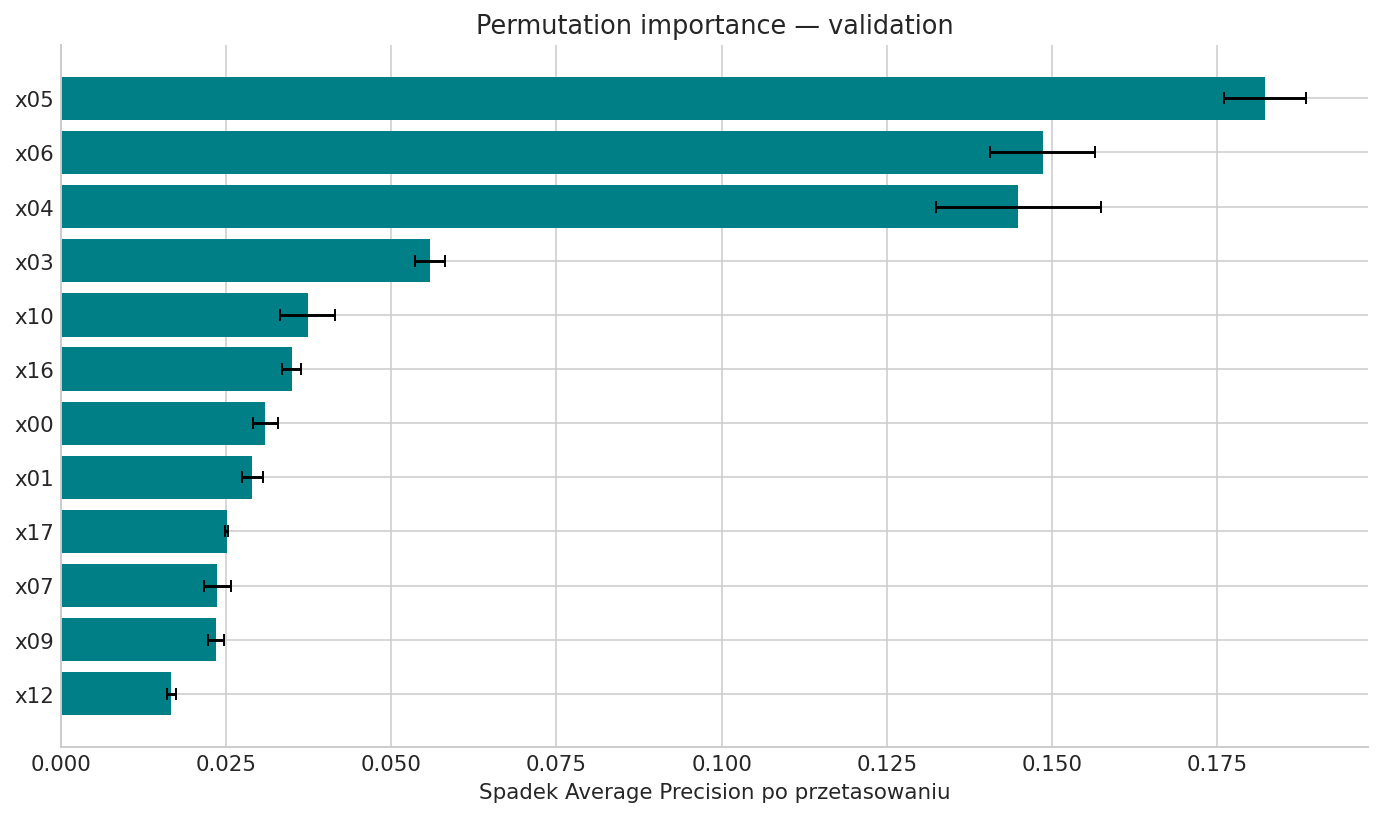

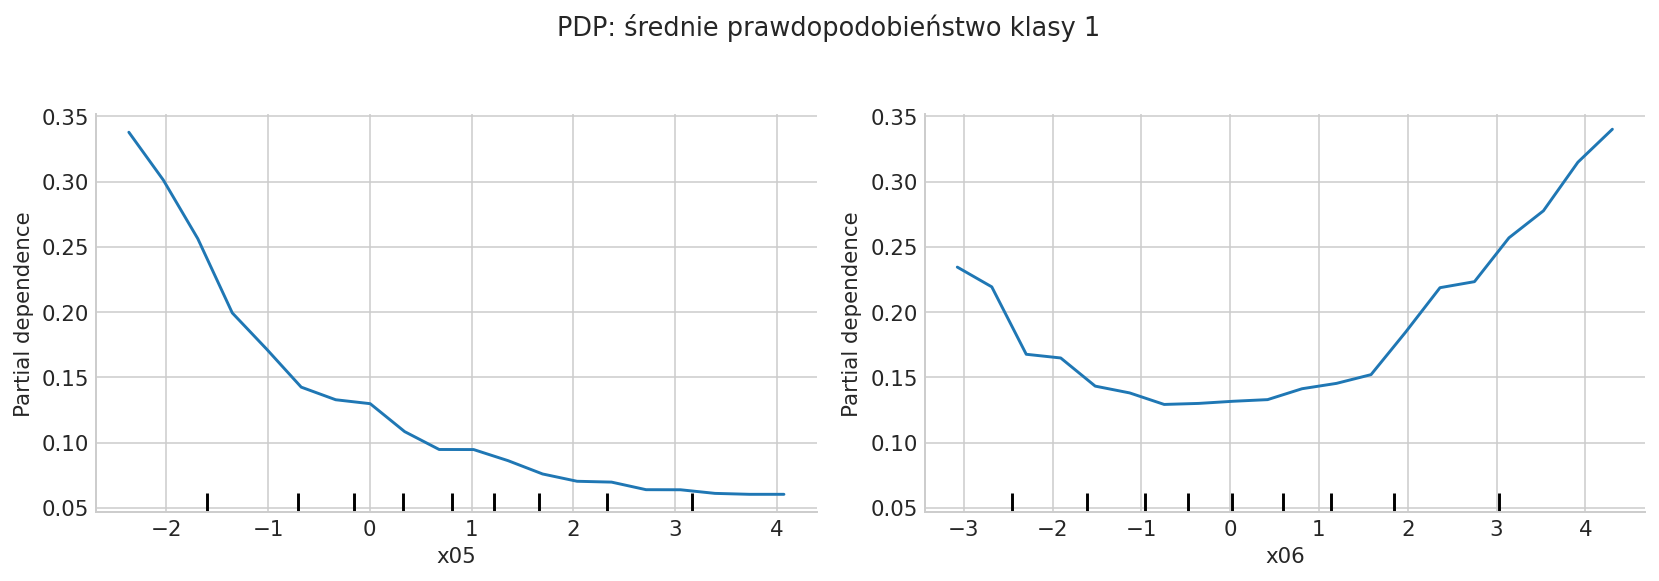

In [13]:
explain_idx, _ = train_test_split(np.arange(len(X_val)), train_size=min(4000, len(X_val)-1),
                                 stratify=y_val, random_state=SEED)
X_explain, y_explain = X_val.iloc[explain_idx], y_val.iloc[explain_idx]
perm = permutation_importance(best, X_explain, y_explain, scoring='average_precision',
                              n_repeats=3, random_state=SEED, n_jobs=1)
importance = pd.DataFrame({'cecha':X.columns, 'spadek_AP':perm.importances_mean,
                          'std':perm.importances_std}).sort_values('spadek_AP',ascending=False)
importance['rola'] = importance.cecha.map(feature_roles).fillna('kategoria pochodna')
display(importance.head(12).round(4))
top=importance.head(12).iloc[::-1]
fig,ax=plt.subplots(figsize=(10,6))
ax.barh(top.cecha,top.spadek_AP,xerr=top['std'],color='#007f86',capsize=3)
ax.set(xlabel='Spadek Average Precision po przetasowaniu',title='Permutation importance — validation')
finish_plot('07_permutation_importance')
top_numeric=[name for name in importance.cecha if name in num_cols][:2]
fig,axes=plt.subplots(1,2,figsize=(12,4))
PartialDependenceDisplay.from_estimator(best, X_explain.iloc[:800], features=top_numeric,
    method='brute', response_method='predict_proba', grid_resolution=20, ax=axes)
fig.suptitle('PDP: średnie prawdopodobieństwo klasy 1',y=1.04)
finish_plot('08_pdp')

### 13. Zamrożenie decyzji przed testem
Od tego momentu nie zmieniamy cech, modelu, hiperparametrów ani progu. Dopasowujemy jedynie dwa wcześniej zdefiniowane punkty odniesienia na train. Test pozwoli porównać ich ranking oraz raportować dwa ustalone warianty decyzji HGB: próg 0.5 i próg F1 wybrany na validation. Żaden z nich nie jest wybierany na podstawie testu.

Zapisujemy też funkcję metryk. AP, ROC AUC, log loss i Brier zależą od prawdopodobieństw; accuracy, precision, recall, F1 i macierz pomyłek zależą od progu. Zmiana progu nie może zmienić AP ani ROC AUC.

In [14]:
frozen_protocol = {'threshold':THRESHOLD, 'threshold_objective':'F1 on validation',
    'params':search.best_params_, 'train_rows':len(X_train), 'seed':SEED}
reference_models = {'Dummy':clone(dummy).fit(X_train,y_train),
                    'Logistic':clone(logistic).fit(X_train,y_train)}
def evaluate(y_true, probabilities, threshold=.5):
    pred=probabilities>=threshold
    tn,fp,fn,tp=confusion_matrix(y_true,pred,labels=[0,1]).ravel()
    return {'AP':average_precision_score(y_true,probabilities),
        'ROC_AUC':roc_auc_score(y_true,probabilities), 'log_loss':log_loss(y_true,probabilities),
        'Brier':brier_score_loss(y_true,probabilities), 'accuracy':accuracy_score(y_true,pred),
        'balanced_accuracy':balanced_accuracy_score(y_true,pred),
        'precision':precision_score(y_true,pred,zero_division=0),
        'recall':recall_score(y_true,pred,zero_division=0), 'F1':f1_score(y_true,pred,zero_division=0),
        'TN':int(tn),'FP':int(fp),'FN':int(fn),'TP':int(tp), 'umowny_koszt':int(5*fn+fp)}
print('Protokół zamrożony. Następna komórka otwiera test.')

Protokół zamrożony. Następna komórka otwiera test.


### 14. Końcowa ocena na nietkniętym teście
Wszystkie kolejne analizy testowe opisują **ten sam zamrożony model**. Nie poprawiamy go na podstawie oglądanych błędów. Jeśli obserwacje zainspirują kolejny eksperyment, do uczciwej końcowej oceny trzeba zaplanować nowy test lub zewnętrzne dane.

**Powiedz:** „Teraz sprawdzamy obietnicę złożoną przez walidację. Test jest egzaminem całego procesu, a nie kolejnym etapem strojenia”.

              precision    recall  f1-score   support

     Klasa 0       0.98      0.99      0.98     17445
     Klasa 1       0.90      0.83      0.86      2555

    accuracy                           0.97     20000
   macro avg       0.94      0.91      0.92     20000
weighted avg       0.97      0.97      0.97     20000



,AP,ROC_AUC,log_loss,Brier,accuracy,balanced_accuracy,precision,recall,F1,TN,FP,FN,TP,umowny_koszt
Dummy @0.5,0.1278,0.5000,0.3821,0.1114,0.8722,0.5000,0.0000,0.0000,0.0000,17445.0,0.0,2555.0,0.0,12775.0
Logistic @0.5,0.6629,0.8588,0.2543,0.0684,0.9142,0.7056,0.8148,0.4254,0.5590,17198.0,247.0,1468.0,1087.0,7587.0
HGB @0.5,0.9122,0.9597,0.1140,0.0276,0.9658,0.8809,0.9575,0.7667,0.8516,17358.0,87.0,596.0,1959.0,3067.0
HGB @próg validation,0.9122,0.9597,0.1140,0.0276,0.9668,0.9083,0.9021,0.8297,0.8644,17215.0,230.0,435.0,2120.0,2405.0


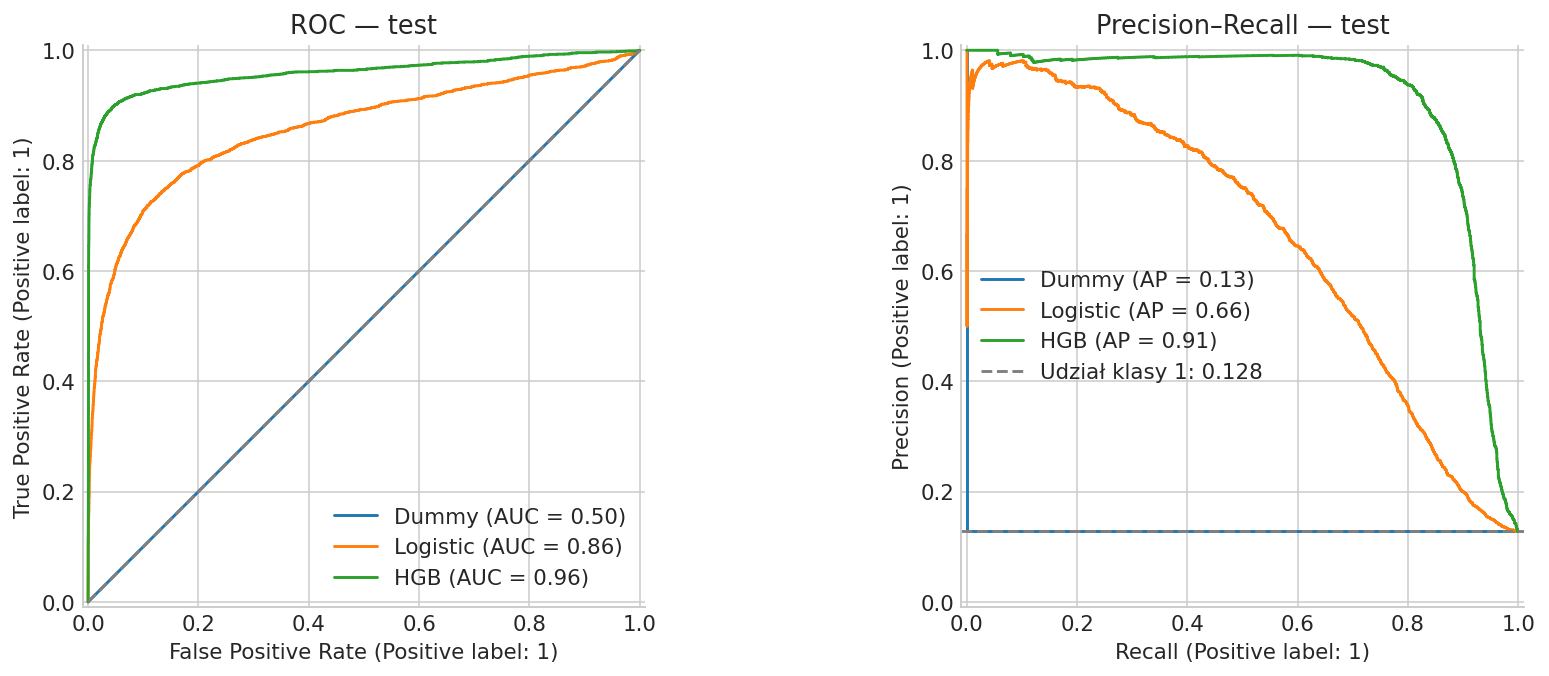

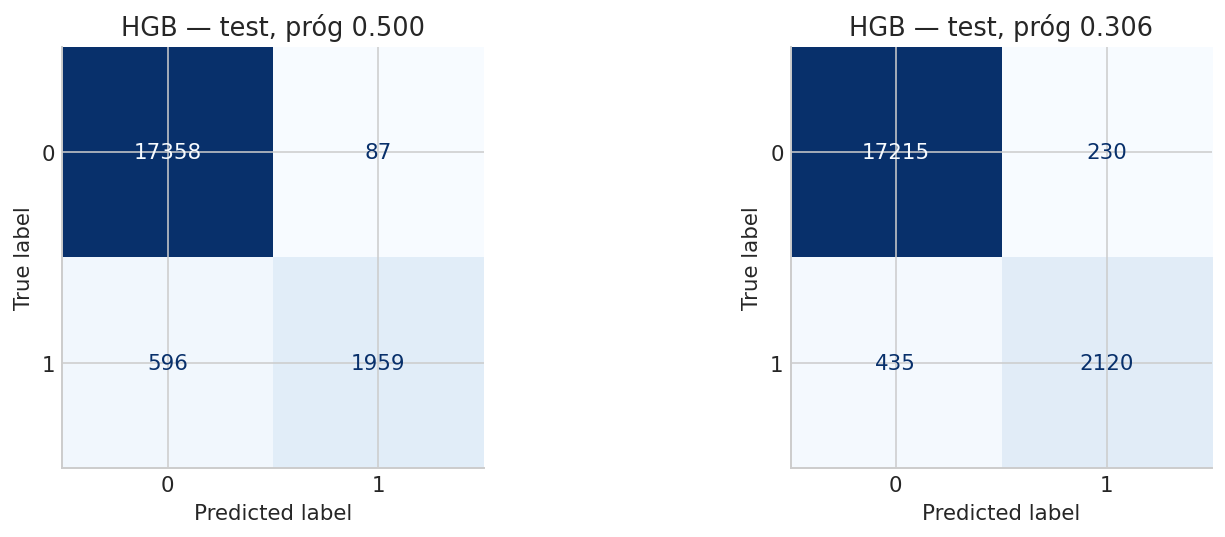

In [15]:
proba_test={name:model.predict_proba(X_test)[:,1] for name,model in reference_models.items()}
proba_test['HGB']=best.predict_proba(X_test)[:,1]
p_test=proba_test['HGB']
test_table=pd.DataFrame({
    'Dummy @0.5':evaluate(y_test,proba_test['Dummy']),
    'Logistic @0.5':evaluate(y_test,proba_test['Logistic']),
    'HGB @0.5':evaluate(y_test,p_test),
    'HGB @próg validation':evaluate(y_test,p_test,THRESHOLD)
}).T
display(test_table.round(4))
print(classification_report(y_test,p_test>=THRESHOLD,target_names=['Klasa 0','Klasa 1'],zero_division=0))
fig,axes=plt.subplots(1,2,figsize=(13,5))
for name,p in proba_test.items():
    RocCurveDisplay.from_predictions(y_test,p,name=name,ax=axes[0])
    PrecisionRecallDisplay.from_predictions(y_test,p,name=name,ax=axes[1])
axes[0].plot([0,1],[0,1],'--',color='gray')
axes[1].axhline(y_test.mean(),ls='--',color='gray',label=f'Udział klasy 1: {y_test.mean():.3f}')
axes[0].set_title('ROC — test'); axes[1].set_title('Precision–Recall — test'); axes[1].legend()
finish_plot('09_roc_pr_test')
fig,axes=plt.subplots(1,2,figsize=(11,4))
for ax,t in zip(axes,[.5,THRESHOLD]):
    ConfusionMatrixDisplay.from_predictions(y_test,p_test>=t,display_labels=['0','1'],
        cmap='Blues',colorbar=False,ax=ax)
    ax.set_title(f'HGB — test, próg {t:.3f}')
finish_plot('10_macierze_pomylek')

### 15. Kalibracja prawdopodobieństw oraz rozkład wyników
Dobry ranking nie oznacza automatycznie dobrych prawdopodobieństw. Jeśli w grupie predykcji około 0.8 klasa 1 występuje w około 80% przypadków, model jest w tym obszarze dobrze skalibrowany. Linia idealna to przekątna. Używamy przedziałów kwantylowych; odstępy na osi X nie muszą być równe.

Brier score mierzy średni kwadrat błędu prawdopodobieństw, ale zależy także od zdolności rozróżniania klas — nie jest czystą miarą kalibracji. Histogram pokazuje stopień nakładania się rozkładów klas. Nie wykonujemy kalibracji po obejrzeniu testu. Ewentualny `CalibratedClassifierCV` trzeba włączyć do nowego procesu uczenia, a potem ponownie wybrać próg bez użycia testu.

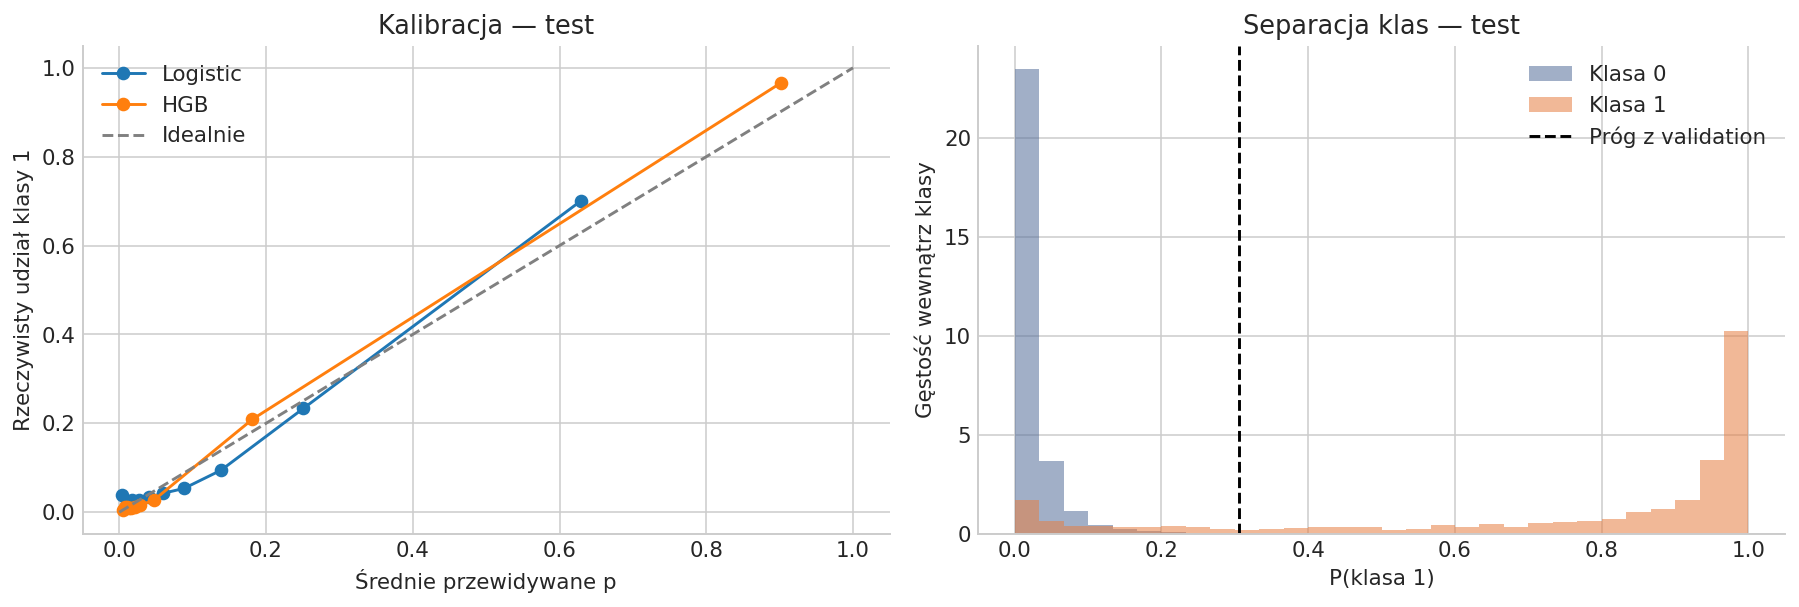

In [16]:
fig,axes=plt.subplots(1,2,figsize=(13,4.5))
for name in ['Logistic','HGB']:
    frac,mean=calibration_curve(y_test,proba_test[name],n_bins=10,strategy='quantile')
    axes[0].plot(mean,frac,'o-',label=name)
axes[0].plot([0,1],[0,1],'--',color='gray',label='Idealnie')
axes[0].set(xlabel='Średnie przewidywane p',ylabel='Rzeczywisty udział klasy 1',title='Kalibracja — test')
axes[0].legend()
for label,color in [(0,'#546e9a'),(1,'#e67e42')]:
    axes[1].hist(p_test[y_test.to_numpy()==label],bins=np.linspace(0,1,31),density=True,
                 alpha=.55,label=f'Klasa {label}',color=color)
axes[1].axvline(THRESHOLD,color='black',ls='--',label='Próg z validation')
axes[1].set(xlabel='P(klasa 1)',ylabel='Gęstość wewnątrz klasy',title='Separacja klas — test'); axes[1].legend()
finish_plot('11_kalibracja_rozklady')

### 16. Ranking operacyjny: ile zdarzeń znajdziemy, sprawdzając tylko część rekordów?
Ustawiamy rekordy malejąco po prawdopodobieństwie klasy 1. Krzywa zysku skumulowanego pokazuje, jaki odsetek wszystkich pozytywów mieści się w pierwszych X% rekordów. **Lift@10%** to częstość pozytywów w top 10% podzielona przez ich częstość w całym teście. Jest użyteczna przy ograniczonej liczbie sprawdzeń, ale nie jest przychodem ani ROI.

Top 10%: precision=0.966, recall=0.756, lift=7.56×


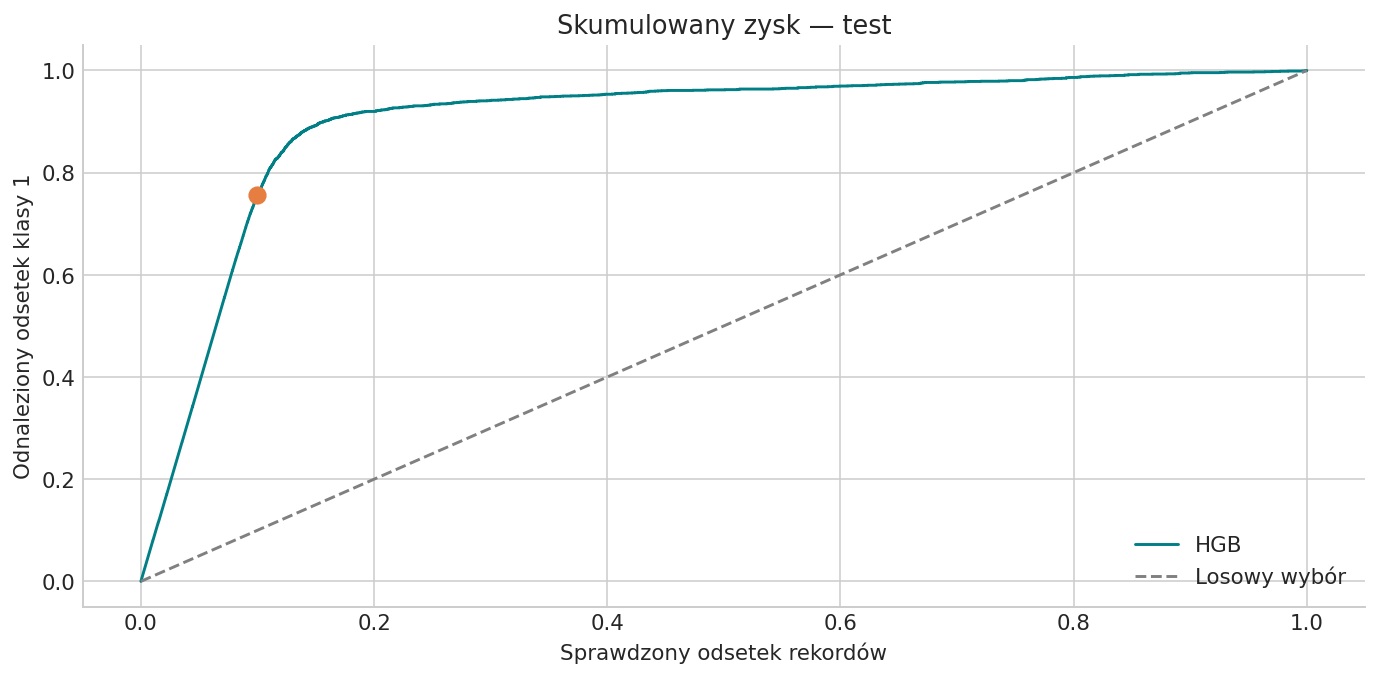

In [17]:
rank=np.argsort(-p_test)
y_rank=y_test.to_numpy()[rank]
coverage=np.arange(1,len(y_rank)+1)/len(y_rank)
gain=np.cumsum(y_rank)/y_rank.sum()
k=max(1,int(.1*len(y_rank)))
precision_at_10=y_rank[:k].mean()
recall_at_10=y_rank[:k].sum()/y_rank.sum()
lift_at_10=precision_at_10/y_test.mean()
fig,ax=plt.subplots()
ax.plot(np.r_[0,coverage],np.r_[0,gain],color='#007f86',label='HGB')
ax.plot([0,1],[0,1],'--',color='gray',label='Losowy wybór')
ax.scatter([coverage[k-1]],[gain[k-1]],color='#e67e42',s=70,zorder=3)
ax.set(xlabel='Sprawdzony odsetek rekordów',ylabel='Odnaleziony odsetek klasy 1',title='Skumulowany zysk — test')
ax.legend(); finish_plot('12_cumulative_gain')
print(f'Top 10%: precision={precision_at_10:.3f}, recall={recall_at_10:.3f}, lift={lift_at_10:.2f}×')

### 17. Niepewność i analiza błędów
Bootstrap losuje ze zwracaniem rekordy testowe i ocenia **ten sam** model. Przedziały percentylowe 95% dla AP i ROC AUC opisują zmienność wynikającą z próbki testowej przy założeniu IID. Nie obejmują zmienności treningu, strojenia, doboru progu ani zmiany rozkładu danych. Wykonujemy 200 powtórzeń jako kompromis szkoleniowy; w raporcie końcowym warto użyć większego budżetu.

Przeglądamy najbardziej pewne pomyłki. W danych syntetycznych część błędów wynika z szumu etykiet i nakładania się klas. Nie wiemy jednak automatycznie, które konkretne etykiety są błędne. W rzeczywistym projekcie potrzebna jest inspekcja danych źródłowych, definicji etykiety i dostępności cech w momencie predykcji.

In [18]:
rng_boot=np.random.default_rng(SEED+7)
y_test_np=y_test.to_numpy()
bootstrap=[]
for _ in range(200):
    ids=rng_boot.integers(0,len(y_test_np),len(y_test_np))
    if np.unique(y_test_np[ids]).size < 2:
        continue
    bootstrap.append([average_precision_score(y_test_np[ids],p_test[ids]),
                      roc_auc_score(y_test_np[ids],p_test[ids])])
boot=np.asarray(bootstrap)
ci=pd.DataFrame({'metryka':['AP','ROC AUC'],
    'wynik':[average_precision_score(y_test,p_test),roc_auc_score(y_test,p_test)],
    'dolny_95':np.quantile(boot,.025,axis=0),'gorny_95':np.quantile(boot,.975,axis=0)})
display(ci.round(4))
errors=X_test.copy()
errors['y']=y_test
errors['p']=p_test
errors['pred']=(p_test>=THRESHOLD).astype(int)
errors['typ']=np.select([(errors.y==0)&(errors.pred==1),(errors.y==1)&(errors.pred==0)],['FP','FN'],default='OK')
errors['pewnosc_blednej_klasy']=np.where(errors.y==0,errors.p,1-errors.p)
display(errors.loc[errors.typ!='OK'].sort_values('pewnosc_blednej_klasy',ascending=False)
        [['y','p','pred','typ','x00','x01','x02','pasmo_x00']].head(10))
# Analiza braków jako przykład segmentacji — tylko opis, bez dostrajania.
errors['liczba_brakow']=X_test[num_cols].isna().sum(axis=1)
segments=[]
for name,mask in [('bez braków',errors.liczba_brakow==0),('co najmniej 1 brak',errors.liczba_brakow>0)]:
    yy=errors.loc[mask,'y']; pp=errors.loc[mask,'p']
    segments.append({'segment':name,'n':int(mask.sum()),'udzial_klasy_1':yy.mean(),
                      'AP':average_precision_score(yy,pp),
                      'recall':recall_score(yy,pp>=THRESHOLD,zero_division=0)})
display(pd.DataFrame(segments).round(4))

,metryka,wynik,dolny_95,gorny_95
0,AP,0.9122,0.9027,0.9223
1,ROC AUC,0.9597,0.9543,0.9651


       y         p  pred typ       x00       x01       x02 pasmo_x00
30474  1  0.001592     0  FN  4.048649  4.744760 -3.542166         C
13711  1  0.002014     0  FN -0.731009 -2.766940  2.103836         B
59662  1  0.002526     0  FN -5.770736 -1.917822       NaN         A
97586  0  0.996817     1  FP -3.245729  0.009310  1.815596         A
75403  1  0.003718     0  FN -1.114933  0.662082  0.099614         A
68750  1  0.004093     0  FN  0.936565  4.292456 -1.152948         B
72281  1  0.004419     0  FN -1.190453 -4.575658 -0.012027         A
95974  0  0.995577     1  FP -1.824259  2.149940 -3.573317         A
67898  1  0.004615     0  FN -4.352839 -2.873972 -0.943860         A
74613  1  0.004955     0  FN -3.097478 -0.253779  0.036484         A

              segment      n  udzial_klasy_1      AP  recall
0          bez braków  12347          0.1306  0.9150  0.8393
1  co najmniej 1 brak   7653          0.1232  0.9077  0.8134

### 18. Automatyczny komentarz do rzeczywiście uzyskanych wyników
Poniższa komórka tworzy omówienie z obliczonych metryk. Nie zakłada z góry, że strojenie lub zmiana progu zawsze poprawia test. Wyższe F1 może oznaczać większą liczbę alarmów; mniejszy umowny koszt jest osobnym kryterium.

In [19]:
a=test_table.loc['HGB @0.5']; b=test_table.loc['HGB @próg validation']
log=test_table.loc['Logistic @0.5']
summary=f"""
**Wyniki pełnego eksperymentu ({N_SAMPLES:,} wierszy):**

- HGB uzyskał **AP={b['AP']:.4f}** i **ROC AUC={b['ROC_AUC']:.4f}** na {len(X_test):,} rekordach testowych.
  Różnica AP wobec regresji logistycznej wynosi **{b['AP']-log['AP']:+.4f}**.
- Próg ustalony na validation to **{THRESHOLD:.4f}**. F1 na teście zmieniło się
  z **{a['F1']:.4f}** do **{b['F1']:.4f}** (różnica **{b['F1']-a['F1']:+.4f}**).
- Przy wybranym progu precision wynosi **{b['precision']:.1%}**, a recall **{b['recall']:.1%}**.
  Oznacza to **{int(b['TP'])}** wykrytych pozytywów, **{int(b['FN'])}** pominiętych oraz **{int(b['FP'])}** fałszywych alarmów.
- Umowny koszt 5×FN+FP: **{int(a['umowny_koszt'])} → {int(b['umowny_koszt'])}**.
  Próg F1 nie musi minimalizować tego kosztu.
- W top 10% rankingu znajduje się **{recall_at_10:.1%}** wszystkich pozytywów;
  lift wynosi **{lift_at_10:.2f}×** względem losowego wyboru.
- Model użył **{core.n_iter_}** iteracji; strojenie i refit trwały **{search_seconds:.1f} s** w tym środowisku.

**Co z tego wynika?** Ranking, jakość prawdopodobieństw i decyzja przy progu to trzy różne właściwości.
Porównaj tabelę metryk, krzywą kalibracji i macierz pomyłek, zanim nazwiesz model „dobrym”.
Wyniki opisują wyłącznie ten syntetyczny rozkład. Przed zastosowaniem potrzebne są rzeczywiste dane,
właściwy podział czasowy lub grupowy, analiza kosztów oraz monitorowanie po uruchomieniu.
"""
display(Markdown(summary))


**Wyniki pełnego eksperymentu (100,000 wierszy):**

- HGB uzyskał **AP=0.9122** i **ROC AUC=0.9597** na 20,000 rekordach testowych.
  Różnica AP wobec regresji logistycznej wynosi **+0.2494**.
- Próg ustalony na validation to **0.3062**. F1 na teście zmieniło się
  z **0.8516** do **0.8644** (różnica **+0.0129**).
- Przy wybranym progu precision wynosi **90.2%**, a recall **83.0%**.
  Oznacza to **2120** wykrytych pozytywów, **435** pominiętych oraz **230** fałszywych alarmów.
- Umowny koszt 5×FN+FP: **3067 → 2405**.
  Próg F1 nie musi minimalizować tego kosztu.
- W top 10% rankingu znajduje się **75.6%** wszystkich pozytywów;
  lift wynosi **7.56×** względem losowego wyboru.
- Model użył **220** iteracji; strojenie i refit trwały **24.9 s** w tym środowisku.

**Co z tego wynika?** Ranking, jakość prawdopodobieństw i decyzja przy progu to trzy różne właściwości.
Porównaj tabelę metryk, krzywą kalibracji i macierz pomyłek, zanim nazwiesz model „dobrym”.
Wyniki opisują wyłącznie ten syntetyczny rozkład. Przed zastosowaniem potrzebne są rzeczywiste dane,
właściwy podział czasowy lub grupowy, analiza kosztów oraz monitorowanie po uruchomieniu.


### 19. Zapis kompletnego modelu i predykcja dla nowych danych
Zapisujemy **cały pipeline**, próg, kolejność kolumn, wersje i protokół. Dzięki temu predykcja nie wymaga ręcznego powtarzania kodowania. `pipeline.predict()` używa domyślnej reguły klasyfikatora; aby zachować nasz próg, korzystamy z `predict_proba()` i jawnego porównania.

Nowe dane w demonstracji zawierają brak oraz nieznaną kategorię. Test po odczycie sprawdza identyczność prawdopodobieństw i decyzji. To techniczny test zapisu, nie nowy pomiar jakości statystycznej.

**Bezpieczeństwo:** `joblib.load` wykonuj wyłącznie dla zaufanego pliku. Pliki joblib/pickle mogą uruchamiać kod. Model odtwarzaj w środowisku zgodnym z zapisanymi wersjami; zgodność między wersjami scikit-learn nie jest gwarantowana.

In [20]:
artifact={'pipeline':best,'threshold':THRESHOLD,'feature_columns':X.columns.tolist(),
          'versions':VERSIONS,'protocol':frozen_protocol,'mode':MODE}
model_path=OUT/'gradient_boosting_pipeline.joblib'
joblib.dump(artifact,model_path)
loaded=joblib.load(model_path)

def predict_new(frame, artifact):
    required=artifact['feature_columns']
    missing=sorted(set(required)-set(frame.columns))
    if missing:
        raise ValueError(f'Brak wymaganych kolumn: {missing}')
    p=artifact['pipeline'].predict_proba(frame.loc[:,required])[:,1]
    return pd.DataFrame({'probability_1':p,'prediction':(p>=artifact['threshold']).astype(int)},index=frame.index)

new_rows=X_val.head(5).copy()
new_rows.iloc[0,new_rows.columns.get_loc('x00')]=np.nan
new_rows.iloc[1,new_rows.columns.get_loc('pasmo_x00')]='NOWA_KATEGORIA'
expected=predict_new(new_rows,artifact)
restored=predict_new(new_rows,loaded)
np.testing.assert_allclose(expected.probability_1,restored.probability_1,rtol=0,atol=1e-12)
assert expected.prediction.equals(restored.prediction)
assert np.isfinite(restored.probability_1).all()
display(restored)
cv_table.to_csv(OUT/'baseline_cv.csv')
cv_results.to_csv(OUT/'search_cv_results.csv',index=False)
test_table.to_csv(OUT/'test_metrics.csv')
importance.to_csv(OUT/'permutation_importance.csv',index=False)
ci.to_csv(OUT/'bootstrap_ci.csv',index=False)
learning_table.to_csv(OUT/'learning_curve.csv',index=False)
(OUT/'omowienie_wynikow.md').write_text(summary,encoding='utf-8')
(OUT/'metadata.json').write_text(json.dumps({'versions':VERSIONS,'protocol':frozen_protocol,
    'n_samples':N_SAMPLES,'elapsed_seconds':time.perf_counter()-run_start},indent=2,ensure_ascii=False),encoding='utf-8')
print('Zapisano model, tabele, wykresy i raport w:',OUT.resolve())
print(f'Łączny czas obliczeń od startu: {time.perf_counter()-run_start:.1f} s')
print('Kontrola zapisu/odczytu oraz predykcja nieznanej kategorii: OK')

Zapisano model, tabele, wykresy i raport w: /workspace/scratch/fa452710b643/output/gradient_boosting_outputs
Łączny czas obliczeń od startu: 40.5 s
Kontrola zapisu/odczytu oraz predykcja nieznanej kategorii: OK


       probability_1  prediction
90615       0.040102           0
57071       0.012908           0
53262       0.022870           0
9733        0.086059           0
44310       0.995197           1

### 20. Ćwiczenia z oczekiwanym kierunkiem interpretacji
1. **Słabsze drzewa:** ustaw `max_leaf_nodes=7`. Czy znika luka trening–walidacja? Jeśli oba wyniki spadają, może to oznaczać niedouczenie. Zmieniaj konfigurację w nowym eksperymencie i nie wykorzystuj starego testu do wyboru zwycięzcy.
2. **Mniejszy krok:** porównaj `learning_rate=0.03, max_iter=700` z `.16, 220`, zachowując te same foldy. Obserwuj jakość oraz czas, a nie samą liczbę drzew.
3. **Wagi klas:** porównaj `class_weight=None` i `'balanced'` w CV. Następnie zbadaj kalibrację i wybierz próg na validation. Wagi nie są obowiązkowym lekarstwem na niezbalansowanie.
4. **Cel operacyjny:** zamiast F1 ustal „maksymalizuj recall przy precision ≥ 0.80” i wybierz próg wyłącznie na validation. Jeśli żaden próg nie spełnia wymagania, zgłoś to zamiast udawać sukces.
5. **Więcej danych:** zmień `N_SAMPLES` na 300 000 (w konfiguracji), zmierz RAM i czas. Nie ekstrapoluj czasu liniowo bez pomiaru.
6. **Cechy redundantne:** usuń `x12–x17` i obie cechy kategoryczne. Zaktualizuj listy kolumn oraz indeksy kategorii. Sprawdź, czy rozkład permutation importance się zmienia. Wnioski o pojedynczej cesze zależą od pozostałych dostępnych cech.
7. **Dane rzeczywiste:** zamień generator na `pd.read_csv`, określ etykietę, usuń cechy powstałe po wyniku i identyfikatory, zaprojektuj podział czasowy/grupowy. Nie traktuj losowego podziału jako ustawienia uniwersalnego.

### Ściąga prowadzącego: pytania i odpowiedzi
| Pytanie | Odpowiedź do omówienia |
|---|---|
| Dlaczego nie skalujemy danych dla HGB? | Drzewa wybierają progi podziałów; standardyzacja nie jest tu wymagana. Regresję logistyczną skalujemy osobno. |
| Czy histogramowy boosting to XGBoost? | Nie. To implementacja scikit-learn z rodziny gradient boosting; XGBoost jest odrębną biblioteką. |
| Czy możemy użyć `GradientBoostingClassifier`? | Tak, ale klasyczna implementacja może być znacznie wolniejsza na dużym zbiorze i wymaga osobnego rozwiązania braków. HGB jest tu świadomym wyborem skali. |
| Po co CV i osobny validation? | CV wybiera hiperparametry, validation ustala próg; test ocenia gotową procedurę. |
| Dlaczego AP jest inne niż accuracy? | AP ocenia ranking bez progu, accuracy liczbę trafnych decyzji przy określonym progu. |
| Czy najlepsza cecha powoduje zmianę etykiety? | Ważność i PDP opisują zachowanie predykcyjne modelu, nie przyczynowość. |
| Czy możemy po obejrzeniu testu dostroić próg? | Wtedy test staje się walidacją; potrzebny będzie nowy niezależny test. |
| Czy model obsługuje dowolne kategorie? | Ten pipeline mapuje nieznane na braki; nie oznacza to, że jego jakość dla nowych kategorii została zweryfikowana. |

### Dokumentacja i źródła
Dokumentację zweryfikowano 20.10.2026. Notebook wykonano na **scikit-learn 1.8.0**, którego wersję wypisuje pierwsza komórka. Strony `stable` mogą opisywać nowszą wersję.
- [HistGradientBoostingClassifier](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html)
- [Metryki i scoring](https://scikit-learn.org/stable/modules/model_evaluation.html)
- [Pułapki i przeciek danych](https://scikit-learn.org/stable/common_pitfalls.html)
- [Pipeline](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html)
- [RandomizedSearchCV](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.RandomizedSearchCV.html)
- [Permutation importance](https://scikit-learn.org/stable/modules/permutation_importance.html)
- [Kalibracja](https://scikit-learn.org/stable/modules/calibration.html)

**Zamknięcie zajęć:** „Kompletny model to więcej niż wywołanie `fit`. Potrzebujemy danych, uczciwej walidacji, jasno określonego celu, właściwego progu i sposobu odtworzenia całej procedury”.